# Machine Learning Foundations: A Guided Course

Start here even if machine learning is new to you. This course builds from a familiar prediction problem to data preparation, training, evaluation, and deployment. Each early lesson introduces the idea in plain language before its formal notes and equations.

**Course path:** 1?2 understand the task; 3?4 learn the mathematical language; 5?8 prepare and validate data; 9?11 understand learning; 12?14 evaluate predictions; 15?18 explore model families; 19?21 follow a complete experiment and deployment; 22?24 continue to algorithms and revise.

**How to study:** read in numbered order. Answer each learning-goal question before continuing. On a first pass, focus on the plain-language explanation and examples; return to equations for precision. The code demonstrations are optional and their saved outputs are included. No prior ML knowledge is required; basic tables and arithmetic are enough to begin.

The running example is predicting delivery time or whether an order will be late. The later synthetic experiment uses a generic binary target to demonstrate the same workflow.

Continue afterward with [the algorithms notebook](ml-algorithms-explained.ipynb). The notebook and website share the same learning content and saved results.


## Contents

1. [The ML problem and vocabulary](#section-1)
2. [Learning paradigms and task types](#section-2)
3. [Essential mathematics](#section-3)
4. [Probability and statistics](#section-4)
5. [Data quality and exploratory analysis](#section-5)
6. [Splitting data and preventing leakage](#section-6)
7. [Cross-validation and model selection](#section-7)
8. [Preprocessing and feature engineering](#section-8)
9. [Bias, variance, and generalization](#section-9)
10. [Loss functions and optimization](#section-10)
11. [Regularization](#section-11)
12. [Regression evaluation](#section-12)
13. [Classification evaluation](#section-13)
14. [Thresholds, imbalance, and calibration](#section-14)
15. [Algorithm intuition at a glance](#section-15)
16. [Clustering and dimensionality reduction](#section-16)
17. [Neural networks and deep learning](#section-17)
18. [Other important ML problem families](#section-18)
19. [A small end-to-end experiment](#section-19)
20. [Error analysis and statistical uncertainty](#section-20)
21. [Deployment, monitoring, and responsible ML](#section-21)
22. [Guide to the algorithms notebook](#section-22)
23. [Interview questions with concise answers](#section-23)
24. [Quick revision checklist and references](#section-24)

### Optional execution setup

Use a Python 3 environment with `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `ipykernel`. If needed, run `%pip install numpy pandas matplotlib scikit-learn ipykernel` in a separate cell, restart the kernel, then **Run All**. No dataset downloads, credentials, or external services are required.

All examples use synthetic data and fixed seeds. Their scores illustrate concepts, not performance claims about a real application. Exact outputs may vary across library versions. The next cell records the environment used to execute this notebook.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

RANDOM_STATE = 42
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.2,
})
display(pd.Series({"Python": sys.version.split()[0], "NumPy": np.__version__,
                   "pandas": pd.__version__, "Matplotlib": matplotlib.__version__,
                   "scikit-learn": sklearn.__version__}, name="Executed with"))

Python          3.12.10
NumPy             2.4.2
pandas            2.3.3
Matplotlib       3.10.8
scikit-learn      1.8.0
Name: Executed with, dtype: object

<a id="section-1"></a>

## 1. The ML problem and vocabulary

### Start with a familiar problem

Suppose a delivery company wants to estimate how long an order will take. A programmer could write rules, but traffic, distance, and demand interact. ML uses past orders with known delivery times to learn a prediction rule. Learning means adjusting that rule using examples; it does not mean the computer understands delivery like a person.

**Learning goal:** Identify one input and the outcome you want to predict.

### Core notes

**Machine learning:** learn a useful mapping or structure from examples, then evaluate whether it generalizes to the intended population.

| Term | Meaning | Example |
|---|---|---|
| Sample / observation | One prediction unit | One order at checkout |
| Feature $X$ | Information available when predicting | Basket value, delivery distance |
| Target $y$ | Outcome to learn | Delivery time |
| Parameter $\theta$ | Learned during fitting | Regression coefficient |
| Hyperparameter | Chosen outside parameter fitting | Tree depth, regularization strength |
| Training / inference | Learning parameters / applying the fitted model | `fit` / `predict` |
| Loss / metric | Training objective / evaluation measure | Cross-entropy / recall |
| Generalization | Performance on relevant unseen cases | Future orders |

Before choosing an algorithm, define **prediction unit, prediction time, target horizon, available features, success metric, and error costs**. “Predict churn” is incomplete; “at month-end, predict whether an active account leaves within 30 days” is testable.

**Baseline:** compare against a simple rule, majority class, mean/median prediction, or seasonal forecast. Complexity must earn its place. A model with high offline accuracy can still be unusable if its predictions arrive too late.

<a id="section-2"></a>

## 2. Learning paradigms and task types

### Choose what kind of answer you need

Predicting delivery minutes is regression. Predicting whether an order arrives late is classification. Grouping orders by similarity without known answers is clustering. The information provided during learning determines the learning paradigm.

**Learning goal:** Is predicting a house price regression or classification? Why?

### Core notes

| Paradigm | Learning signal | Typical use |
|---|---|---|
| Supervised | Labeled examples $(X,y)$ | Classification, regression |
| Unsupervised | Structure in $X$ | Clustering, compression |
| Semi-supervised | Few labeled + many unlabeled examples | Classification with costly labels |
| Self-supervised | Targets constructed from the data | Predict masked tokens or image regions |
| Reinforcement learning | Rewards from sequential actions | Control, policy learning |

**Regression:** continuous target. **Binary classification:** two classes. **Multiclass:** one of several classes. **Multilabel:** several labels can apply simultaneously. **Ranking:** relative ordering matters. **Forecasting:** predict future values with temporal constraints.

**Discriminative models** learn a decision rule or $P(y\mid X)$; **generative models** model how data are distributed or generated, such as $P(X\mid y)P(y)$. This statistical distinction is broader than the popular use of “generative AI.”

**Batch learning** fits on a collected dataset; **online learning** updates incrementally. Neither automatically solves changing data distributions.

<a id="section-3"></a>

## 3. Essential mathematics

### Read the symbols without fear

A feature is one measurable input. A row is one example. X is the whole input table; y is its answer column. In a formula, a subscript identifies an entry and a summation sign means add the listed terms. A weight controls how strongly an input affects the prediction. You can understand the workflow before mastering every equation.

**Learning goal:** For 100 orders with 4 input measurements each, what is the shape of X?

### Core notes

| Concept | Compact reminder | Why it matters |
|---|---|---|
| Vector / matrix | $x\in\mathbb{R}^d$, $X\in\mathbb{R}^{n\times d}$ | Samples are rows, features are columns |
| Dot product | $w^Tx=\sum_j w_jx_j$ | Linear score; similarity |
| Norm | $\|x\|_2=\sqrt{\sum_jx_j^2}$ | Distance and regularization |
| Derivative / gradient | Rate of change / vector of partial derivatives | Direction for optimization |
| Chain rule | Differentiate composed functions | Backpropagation |
| Eigenvectors / SVD | Directions and strength of matrix variation | PCA, low-rank approximation |

Linear prediction: $\hat y=Xw+b$, where $w$ has $d$ entries and $\hat y$ has $n$ entries. Broadcasting errors can produce a plausible-looking but wrong matrix, so check shapes.

Euclidean distance measures absolute separation; cosine similarity $x^Tz/(\|x\|_2\|z\|_2)$ compares direction and is undefined for zero vectors. Feature units can dominate distances.

**Convex objective:** every local minimum is global, but a minimizer need not be unique. Neural-network objectives are generally nonconvex. Optimization success on training loss does not guarantee generalization.

<a id="section-4"></a>

## 4. Probability and statistics

### Reason about uncertainty

Predictions are uncertain because examples vary and our measurements are incomplete. A probability of 0.8 means an estimated 80% chance under the model, not a guarantee. Statistics helps us distinguish patterns supported by data from patterns that may be sampling noise.

**Learning goal:** Why should a rare event make you cautious about interpreting an alert?

### Core notes

**Expectation** is a probability-weighted average. **Variance** measures spread around the mean. **Covariance** measures joint variation; Pearson correlation normalizes covariance and detects linear association. Zero correlation does not imply independence in general.

Bayes' rule:

$$P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}.$$

Posterior = likelihood × prior / evidence. If an event occurs in 1% of cases, a detector has 90% recall, and its false-positive rate is 5%, then a positive result has probability
$0.009/(0.009+0.0495)\approx15.4\%$ of being a true event. **Base rates matter.**

- **Maximum likelihood (MLE):** choose parameters that maximize the probability of observed data. **MAP:** also incorporate a parameter prior; common priors correspond to regularization penalties.
- **Sampling:** training data may differ from the population through selection, survivorship, or measurement bias. More biased data do not necessarily help.
- **Law of large numbers:** sample averages stabilize under suitable assumptions. **Central limit theorem:** suitably normalized averages approach a normal distribution under suitable conditions; the original data need not be normal.
- **Confidence interval:** a procedure with stated long-run coverage, not a probability statement about a fixed parameter after observing one interval.
- **p-value:** probability, under the null model, of results at least as extreme as observed; not the probability the null is true. Statistical significance is not practical importance.
- **Correlation is not causation:** a predictive feature may be a proxy or confounder. Intervention questions require causal assumptions and often randomized experiments.

<a id="section-5"></a>

## 5. Data quality and exploratory analysis

### Inspect the examples before learning

A dataset is a table of examples. First ask what each row represents and how each column was collected. A delivery duration of minus ten minutes suggests a data error; an unusually long delivery may be a legitimate case. Explore the data to understand its meaning before trying to fix it.

**Learning goal:** Name one data error and one unusual but valid observation.

### Core notes

Start with the schema and prediction unit, then inspect missingness, duplicates, ranges, category frequencies, label balance, and feature availability. Explore feature–target relationships on the training portion after designing the split.

| Issue | Useful response | Common mistake |
|---|---|---|
| Missing values | Investigate cause; impute within training folds; consider indicators | Treat all missingness as random |
| Duplicates / repeated entities | Identify provenance and choose entity-aware splits | Put copies of one event in train and test |
| Outliers | Check units and data entry; consider robust methods | Delete all unusual but legitimate cases |
| Noisy labels | Audit examples and labeling rules | Tune endlessly against inconsistent labels |
| Imbalance | Inspect class prevalence and error costs | Report accuracy alone |
| High-cardinality IDs | Check whether they generalize to new entities | Learn an identifier lookup table |

Missingness can be **MCAR** (unrelated to observed or missing values), **MAR** (explained by observed values), or **MNAR** (still related to unobserved values). These mechanisms are assumptions, not labels an imputer can reliably discover.

Document units, target construction, sample exclusions, and data provenance. A clean-looking table can still contain future information.

<a id="section-6"></a>

## 6. Splitting data and preventing leakage

### Practice exams versus a final exam

Training examples are practice material with answers. Validation examples help choose how to study. Test examples are the final exam. If you study the final exam answers while making choices, its score no longer measures performance on unfamiliar questions.

**Learning goal:** Why must the test set stay separate from model choices?

### Core notes

**Training** learns parameters; **validation** guides model, feature, and threshold choices; **test** estimates performance of the frozen procedure. A 60/20/20 split is only an example: choose sizes that support representative evaluation.

| Data structure | Split choice | What it protects against |
|---|---|---|
| Approximately independent rows | Random split | Accidental ordering effects |
| Classification with rare labels | Stratified split | Very different class proportions |
| Repeated users, devices, documents | Group split | Memorization across related rows |
| Future predictions | Forward time split; gap if needed | Learning from the future |

**Leakage:** evaluation benefits from information unavailable during genuine prediction. Examples: scaling on all data, selecting features with all labels, oversampling before splitting, or including a field created after the outcome. Fit learned transformations within the training fold; apply their fitted versions to validation/test. A pipeline handles transformation boundaries, but cannot repair a leaked feature definition or an inappropriate split.

Group and temporal constraints may both matter. Stratification alone does not enforce either. Keep test results out of iterative decisions.

Reference: [scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html).

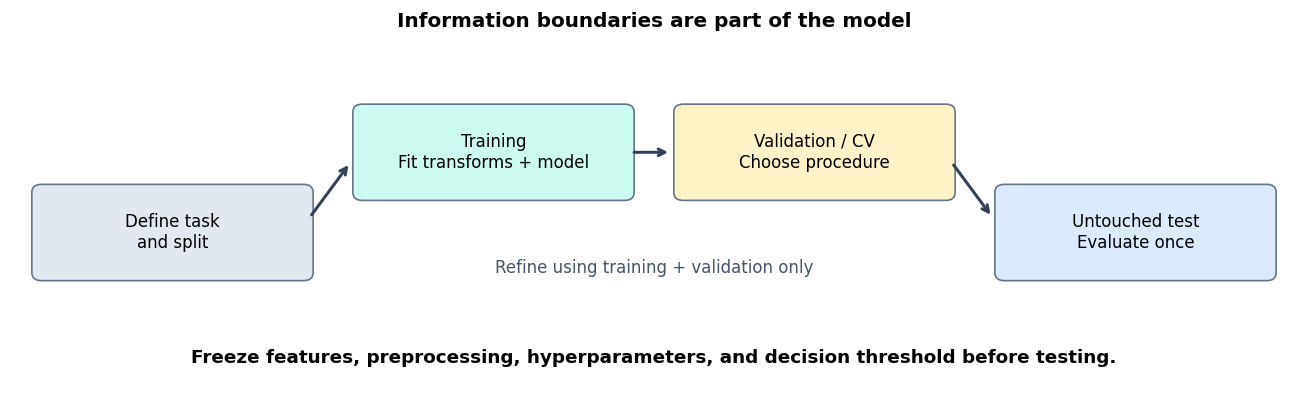

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set(xlim=(0, 11), ylim=(0, 3.6))
ax.axis("off")
boxes = [
    (0.25, 1.35, "Define task\nand split", "#e2e8f0"),
    (3.0, 2.15, "Training\nFit transforms + model", "#ccfbf1"),
    (5.75, 2.15, "Validation / CV\nChoose procedure", "#fef3c7"),
    (8.5, 1.35, "Untouched test\nEvaluate once", "#dbeafe"),
]
for x, y, label, color in boxes:
    ax.add_patch(FancyBboxPatch((x, y), 2.25, 0.8,
                               boxstyle="round,pad=0.08", facecolor=color,
                               edgecolor="#64748b"))
    ax.text(x + 1.125, y + 0.4, label, ha="center", va="center", fontsize=10)
for start, end in [((2.55, 1.9), (2.9, 2.45)), ((5.3, 2.55), (5.65, 2.55)),
                   ((8.05, 2.45), (8.4, 1.9))]:
    ax.annotate("", xy=end, xytext=start,
                arrowprops={"arrowstyle": "->", "color": "#334155", "lw": 1.8})
ax.text(5.5, 1.35, "Refine using training + validation only", ha="center", color="#475569")
ax.text(5.5, 0.45, "Freeze features, preprocessing, hyperparameters, and decision threshold before testing.",
        ha="center", fontsize=11, weight="bold")
ax.set_title("Information boundaries are part of the model", pad=12)
plt.tight_layout()
plt.show()

**Figure takeaway:** information flows from training into fitted transformations and the model. Validation supports choices; test outcomes must not feed back into those choices. After selection, a fixed procedure can be refitted on development data before final testing, provided all learned decision components remain valid.

<a id="section-7"></a>

## 7. Cross-validation and model selection

### Repeat the practice exam fairly

A single validation split can be lucky or unlucky. Cross-validation repeats training and validation across different portions of development data. Every repetition must learn its preprocessing from its own training portion.

**Learning goal:** What changes between folds, and what must remain untouched?

### Core notes

**K-fold CV:** fit on K−1 folds and evaluate on the remaining fold, rotating the holdout. Report the mean and variation, not just the best fold. Use stratified, grouped, or temporal variants to match the deployment question.

**Model selection:** grid search enumerates combinations; random search samples them; Bayesian optimization uses past trials to guide subsequent choices. Tune preprocessing together with the estimator. In scikit-learn, losses used as search scores commonly have a `neg_` prefix because larger scores are preferred.

**Nested CV:** inner folds select settings; outer folds estimate the selection procedure's performance. Alternatively, tune on development data and evaluate once on a separate test set. Repeatedly trying settings against one validation set can overfit it too.

**Out-of-fold predictions:** each row is predicted by a model that did not train on that row. They support stacking and development diagnostics. Fold scores are correlated because training sets overlap; their standard deviation is not automatically a confidence interval.

Reference: [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).

<a id="section-8"></a>

## 8. Preprocessing and feature engineering

### Turn raw columns into useful inputs

Models need consistent numeric representations. Missing values need a policy, categories need an encoding, and measurements with very different units may need scaling. Learn these conversion rules from training data, then apply the same rules to new examples.

**Learning goal:** Why should an unseen category not crash prediction?

### Core notes

| Operation | Use | Caveat |
|---|---|---|
| Standardization | $(x-\mu_{train})/\sigma_{train}$; scaling for distance/gradient methods | Does not make a feature Gaussian |
| Min–max scaling | Map training range to a chosen interval | New values can fall outside that interval |
| Robust scaling | Median and interquartile range | Does not remove outliers |
| One-hot encoding | Unordered categories | Handle unseen categories and large vocabularies |
| Ordinal encoding | Meaningful ordered categories | Arbitrary integer codes imply artificial order |
| Target encoding | Summaries using category targets | Requires training-only, out-of-fold construction |
| Log transform | Compress positive skew | Handle zero/negative values intentionally |
| Feature interactions | Products, ratios, domain features | Can inflate dimensionality and overfitting |

Scaling usually matters for KNN, SVM, regularized linear models, PCA, and neural networks; ordinary axis-aligned trees generally do not need it. “Normalization” can mean several things: specify whether you mean feature scaling or unit-length rows.

**Feature selection** retains original features (filters, wrappers such as recursive elimination, or embedded selection). **Feature extraction** creates new representations, such as PCA components. Both belong inside validation when they learn from data.

Use `ColumnTransformer` for column-specific steps and `Pipeline` for fit/transform order. For text, fit vocabulary and IDF on training data; for dates, construct only information known at prediction time.

Reference: [scikit-learn: preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html).

<a id="section-9"></a>

## 9. Bias, variance, and generalization

### Learning a pattern versus memorizing examples

A very simple rule may miss useful relationships. An extremely flexible rule may memorize accidents in the training examples. We want a model that works on new cases, so we compare its training and validation errors.

**Learning goal:** What does low training error with much higher validation error suggest?

### Core notes

**Underfitting:** model misses learnable structure; training and validation errors are both high. Try better features, more capacity, less regularization, or better optimization.

**Overfitting:** model captures sample-specific noise; training error is low but validation error is worse. Try more representative data, stronger regularization, simpler models, or early stopping. First rule out leakage and distribution mismatch.

**Bias** is systematic error across possible training sets; **variance** is sensitivity to the sampled training set. For squared-error prediction under the usual zero-mean noise assumptions:

$$\mathbb{E}[(y-\hat f(x))^2]=\mathrm{Bias}[\hat f(x)]^2+\mathrm{Var}[\hat f(x)]+\sigma^2.$$

This decomposition is about repeated datasets, not one residual. Irreducible noise limits performance given the available inputs.

**Learning curve:** performance versus training-set size. **Validation curve:** performance versus a hyperparameter. A large train–validation gap suggests variance or mismatch, not proof of a single cause. More data tends to help variance more than structural underfitting. Real curves need not form a perfect U-shape.

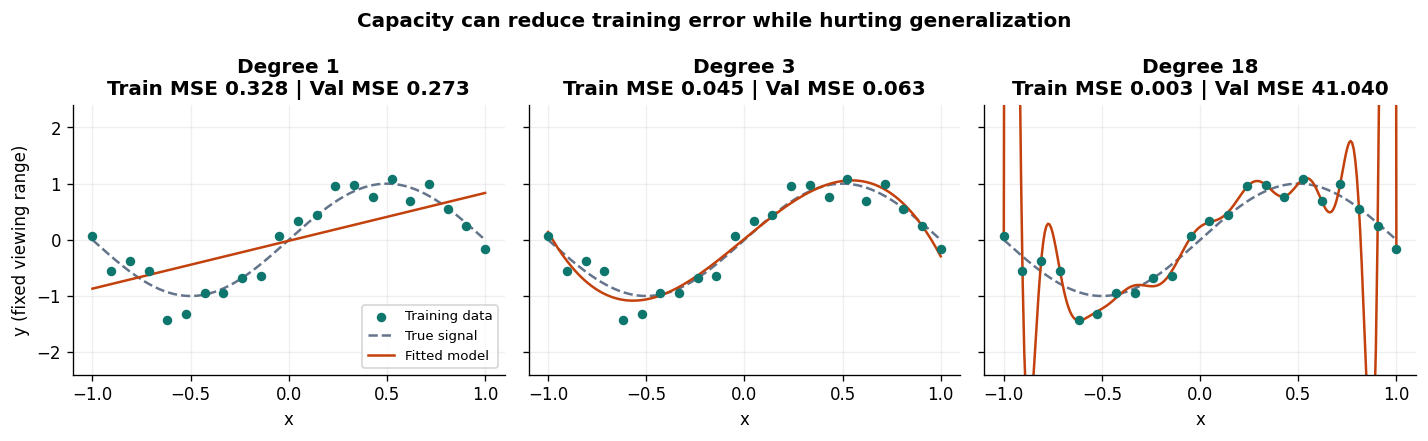

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(RANDOM_STATE)
x_fit = np.linspace(-1, 1, 22)
y_fit = np.sin(np.pi * x_fit) + rng.normal(0, 0.25, len(x_fit))
x_validation = np.linspace(-1, 1, 250)
y_validation = np.sin(np.pi * x_validation) + rng.normal(0, 0.25, len(x_validation))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
for ax, degree in zip(axes, [1, 3, 18]):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression())
    model.fit(x_fit[:, None], y_fit)
    train_mse = mean_squared_error(y_fit, model.predict(x_fit[:, None]))
    valid_mse = mean_squared_error(y_validation, model.predict(x_validation[:, None]))
    ax.scatter(x_fit, y_fit, s=22, color="#0f766e", label="Training data", zorder=3)
    ax.plot(x_validation, np.sin(np.pi * x_validation), "--", color="#64748b", label="True signal")
    ax.plot(x_validation, model.predict(x_validation[:, None]), color="#c2410c", label="Fitted model")
    ax.set(title=f"Degree {degree}\nTrain MSE {train_mse:.3f} | Val MSE {valid_mse:.3f}",
           xlabel="x", ylim=(-2.4, 2.4))
axes[0].set_ylabel("y (fixed viewing range)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Capacity can reduce training error while hurting generalization", weight="bold")
plt.tight_layout()
plt.show()

**Figure takeaway:** compare the reported validation errors, not visual smoothness alone. The high-degree fit can oscillate sharply between observations; portions outside the fixed y-range are clipped for comparison. This is a controlled illustration, not evidence that degree 3 is universally best.

<a id="section-10"></a>

## 10. Loss functions and optimization

### How a model improves

A loss assigns a penalty to a wrong prediction. Training adjusts model parameters to reduce average penalty. A gradient tells us how a small parameter change affects loss, and an optimizer uses that information to choose the next update.

**Learning goal:** Explain the difference between the loss and the optimizer.

### Core notes

Empirical risk minimization minimizes average training loss, often with a regularization penalty:

$$J(\theta)=\frac1n\sum_{i=1}^{n}L(y_i,f_\theta(x_i))+\lambda\Omega(\theta).$$

| Loss | Typical use | Intuition |
|---|---|---|
| Squared error $(y-\hat y)^2$ | Regression | Large errors get strong penalties |
| Absolute error $\lvert y-\hat y\rvert$ | Regression | Less sensitive to extreme residuals |
| Huber | Robust regression | Quadratic near zero, linear for large errors |
| Binary cross-entropy | Binary probability prediction | Penalizes confident wrong probabilities |
| Multiclass cross-entropy | One-of-K classification | Negative log probability of the true class |
| Hinge | Margin-based classification | Penalizes margin violations |

Gradient descent: $\theta_{t+1}=\theta_t-\eta\nabla J(\theta_t)$. **Learning rate $\eta$** too large can diverge; too small can stall. **Batch** uses all samples per update; **stochastic** uses one; **mini-batch** uses a subset. An **epoch** is one pass through training data; an **iteration** is one update.

Momentum accumulates direction; Adam uses adaptive moment estimates. Neither guarantees the best generalization. Scaling, initialization, schedules, and convergence checks matter. Backpropagation computes gradients; the optimizer uses them to update parameters.

Loss and reported metric can differ: optimize differentiable cross-entropy, then evaluate a decision metric such as F1 or recall at a chosen threshold.

<a id="section-11"></a>

## 11. Regularization

### Discourage unnecessarily complicated rules

Regularization adds a preference for simpler or more stable solutions. Think of it as asking a learner to explain the evidence using a rule that is not excessively sensitive to individual examples. Too much simplification can also lose useful signal.

**Learning goal:** Why can stronger regularization help validation but hurt training fit?

### Core notes

- **L2 / Ridge:** penalize $\sum_j w_j^2$; shrink coefficients smoothly. Useful with correlated predictors; does not usually create exact zeros.
- **L1 / Lasso:** penalize $\sum_j |w_j|$; can produce sparse coefficients. With correlated features, selected features can be unstable.
- **Elastic Net:** combine L1 and L2. Scale features so penalties are comparable across coefficients.
- **Tree constraints:** depth, minimum leaf size, pruning, and related controls limit complexity.
- **Early stopping:** stop using a validation criterion; it is a model-selection decision.
- **Dropout / augmentation:** regularize neural networks by perturbing hidden activations / training inputs. Augmentation must preserve the target and stay within the training partition.

Larger $\lambda$ generally means stronger regularization; in scikit-learn logistic regression and SVM, larger **C** means weaker regularization. Parameter conventions differ across estimators. The intercept is often treated differently from other coefficients.

**Linear-regression assumptions:** linear conditional mean and exogeneity matter for coefficient interpretation; perfect multicollinearity prevents a unique ordinary least-squares solution. Homoscedasticity and independent errors support classical standard errors. Normal errors support certain exact small-sample inference results, but normal features are not required for fitting or prediction. Polynomial features are nonlinear in inputs while remaining linear in coefficients.

Reference: [scikit-learn: linear models](https://scikit-learn.org/stable/modules/linear_model.html).

<a id="section-12"></a>

## 12. Regression evaluation

### Measure mistakes in numeric predictions

If the true delivery time is 30 minutes and the prediction is 40, the absolute error is 10 minutes. Repeating this calculation across unseen orders gives an error summary. Different metrics emphasize different kinds of mistakes.

**Learning goal:** Would one very large error affect MAE or RMSE more strongly?

### Core notes

Let $e_i=y_i-\hat y_i$.

| Metric | Formula | Interpretation |
|---|---|---|
| MAE | $\frac1n\sum_i\lvert e_i\rvert$ | Typical absolute error in target units |
| MSE | $\frac1n\sum_i e_i^2$ | Strong penalty on large residuals; squared units |
| RMSE | $\sqrt{\frac1n\sum_i e_i^2}$ | Target units; sensitive to large residuals |
| $R^2$ | $1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}$ | Relative to predicting the evaluation-set mean |

$R^2$ can be negative on unseen data; it is not “percent accuracy.” Its usual formula is undefined for a constant target. MAPE is unstable near zero and undefined at zero without implementation conventions. Select a metric that reflects the costs of mistakes.

Under ideal population risk minimization, squared loss targets the conditional **mean**, absolute loss the conditional **median**, and quantile loss a chosen conditional **quantile**.

Inspect residuals versus predictions, time, and important groups. Structure suggests missing signal or mismatch; a funnel shape suggests nonconstant error variance. Reversing a log transform can require bias correction when the goal is the original-scale conditional mean.

<a id="section-13"></a>

## 13. Classification evaluation

### Count the kinds of label mistakes

For a late-delivery alert, positive means late. A false positive warns about an order that is actually on time. A false negative misses a late order. Which error matters more depends on what happens after the alert.

**Learning goal:** Describe a false positive and a false negative in another application.

### Core notes

Choose the **positive class** explicitly. A confusion matrix has true labels on rows and predicted labels on columns in scikit-learn.

| Actual / predicted | Negative | Positive |
|---|---|---|
| Negative | TN: true negative | FP: false positive |
| Positive | FN: false negative | TP: true positive |

| Metric | Formula | Question answered |
|---|---|---|
| Accuracy | $(TP+TN)/N$ | How often are labels correct? |
| Precision | $TP/(TP+FP)$ | Of positive predictions, how many are correct? |
| Recall / TPR | $TP/(TP+FN)$ | Of actual positives, how many are found? |
| Specificity / TNR | $TN/(TN+FP)$ | Of actual negatives, how many are rejected? |
| FPR | $FP/(FP+TN)$ | Of actual negatives, how many trigger an alert? |
| F1 | $2PR/(P+R)$ | Harmonic balance of precision and recall |
| Balanced accuracy | $(TPR+TNR)/2$ for binary tasks | Equal weight to class recalls |

For example, TP=30, FP=10, FN=20, TN=940 gives accuracy 97%, precision 75%, recall 60%, and F1 about 66.7%. A majority-only predictor reaches 95% accuracy but detects no positives.

**Macro** averaging treats classes equally; **weighted** averaging weights by support; **micro** aggregates counts. In single-label multiclass classification over all classes, micro precision/recall/F1 equal accuracy. State conventions when a denominator is zero.

**ROC-AUC** measures ranking across thresholds; **precision–recall curves** highlight positive-class retrieval. Average precision summarizes precision at recall increases and is not identical to trapezoidal PR area. For rare positives, compare AP with prevalence and inspect actual precision/recall at the operating threshold. AUC is not a calibration measure.

Reference: [scikit-learn: evaluation metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).

<a id="section-14"></a>

## 14. Thresholds, imbalance, and calibration

### Turn a probability into a decision

A model may assign a 30% chance of lateness. Whether that deserves an alert is a separate decision. Lowering the alert threshold catches more late orders but usually creates more alerts to review.

**Learning goal:** Why might two teams use different thresholds for the same model?

### Core notes

**Scores → probabilities → actions are different steps.** A default probability threshold of 0.5 is not a universal optimum. Lowering a threshold cannot reduce recall for fixed scores, but empirical precision need not change monotonically.

- **Imbalanced labels:** consider class weights, training-fold-only resampling, better data collection, and threshold selection. Synthetic oversampling before splitting leaks information.
- **Decision costs:** with calibrated binary probabilities, fixed costs, and zero cost for correct decisions, predict positive when $p>C_{FP}/(C_{FP}+C_{FN})$. Capacity limits or other utilities can change this rule.
- **Calibration:** among cases assigned probability 0.8, roughly 80% should be positive. Reliability curves compare predicted and observed rates; small bins can be noisy.
- **Log loss and Brier score:** evaluate probabilistic predictions. They reflect more than calibration alone. A model can rank well but assign poor probabilities.
- **Calibration fitting:** use held-out development data or cross-validation. Do not calibrate or choose thresholds on the final test labels.

Class weighting and resampling can alter probability interpretation. Evaluate probabilities and decisions at the intended deployment prevalence. Threshold adjustments change decisions, not the underlying ranking.

Reference: [scikit-learn: probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

<a id="section-15"></a>

## 15. Algorithm intuition at a glance

These are conceptual reminders; the companion notebook provides worked code. KNN, SVM, trees, and forests have both classification and regression variants even though the companion primarily demonstrates classifiers.

| Family | Core idea | Main controls / failure mode |
|---|---|---|
| Linear regression | Weighted sum predicts a number | Misspecified relationship, correlated coefficients, outliers |
| Logistic regression | Linear log-odds mapped through sigmoid | Regularization, scaling; linear boundary in feature space |
| KNN | Predict using nearby examples | Small k: variance; large k: smoothing; distance and scale |
| SVM | Large-margin separator; kernels provide implicit feature-space similarity | C, kernel, gamma; kernel methods can be costly at scale |
| Naive Bayes | Bayes rule with features conditionally independent given class | Distribution choice, smoothing; correlated evidence can distort probabilities |
| Decision tree | Greedy splits reduce impurity or regression loss | Depth / leaf size; unstable deep trees |
| Bagging | Average models trained on bootstrap samples | Reduces variance when model errors are not too correlated |
| Random forest | Bagged trees with random candidate features per split | Tree correlation, leaf size, feature subsampling |
| AdaBoost | Sequentially emphasize difficult examples | Weak learner, learning rate; noisy labels can hurt |
| Gradient boosting | Add learners following the negative loss gradient | Learning rate, tree complexity, number of rounds |
| Neural network | Compose learned nonlinear transformations | Architecture, optimizer, regularization, data requirements |

Tree **Gini impurity** is $1-\sum_k p_k^2$; **entropy** is $-\sum_k p_k\log p_k$. A split seeks a weighted impurity decrease, not a causal explanation. Tree-based regression often struggles to extrapolate beyond observed target ranges.

**Voting** combines predictions; **stacking** learns a meta-model from out-of-fold base-model predictions. Training the meta-model on in-sample predictions can overfit. Ensembles are most useful when members offer complementary errors.

Reference: [scikit-learn: ensembles](https://scikit-learn.org/stable/modules/ensemble.html).

<a id="section-16"></a>

## 16. Clustering and dimensionality reduction

**K-means** minimizes within-cluster squared Euclidean distance to centroids. Choose k, scale meaningfully, and use multiple initializations. It favors compact clusters and can fail with outliers, unequal densities, or non-spherical groups. Cluster IDs are arbitrary, not class labels.

**DBSCAN** finds dense regions and labels some points as noise; density parameters and varying densities are challenges. **Hierarchical clustering** builds nested groups; linkage and distance define the result. **Gaussian mixtures** provide soft membership under a mixture distribution model.

**Evaluation:** inertia decreases as k grows, so minimum inertia alone cannot choose k. An elbow may be unclear. Silhouette compares within-cluster and nearest-other-cluster distances (roughly −1 to 1); it favors some geometries and needs at least two clusters. With reference labels, adjusted Rand index handles label permutations. Always check stability and usefulness.

**PCA** finds orthogonal directions of maximum variance in centered data, often after scaling. It is unsupervised: high variance need not mean high predictive value. Components are uncorrelated on the fitted data, not necessarily statistically independent. Explained variance is not classification accuracy.

**Curse of dimensionality:** neighborhoods become sparse and distance less informative without structure. Feature selection or compression can help, but may discard useful low-variance signal. t-SNE/UMAP are exploratory embeddings; visually separated islands alone do not establish real clusters. When PCA feeds a supervised model, fit it inside training folds.

<a id="section-17"></a>

## 17. Neural networks and deep learning

A layer computes $h=\phi(Wx+b)$. Without nonlinear activations, stacked linear layers collapse into one linear transformation.

| Concept | Short note |
|---|---|
| ReLU | $\max(0,z)$; simple activation, but units can become inactive |
| Sigmoid / softmax | Binary probability / normalized multiclass scores; normalization does not guarantee calibration |
| Backpropagation | Chain rule computes gradients through the network |
| Vanishing / exploding gradients | Gradients become too small / large through repeated transformations |
| Batch normalization | Uses batch statistics in training and running statistics at inference in common implementations |
| Dropout | Randomly disables activations during training; disabled at inference in the standard prediction path |
| CNN | Shared local filters; strong image/spatial inductive bias |
| RNN / LSTM | Sequential state; long dependencies can be difficult |
| Transformer | Attention lets representations depend on other positions |
| Transfer learning | Reuse pretrained representations; freeze layers or fine-tune |

Attention combines values using weights derived from query–key similarity; positional information is needed to represent sequence order. Embeddings are learned vector representations. Self-supervised pretraining can make labeled-data training more efficient.

Deep learning is not automatically best for small tabular datasets. Compare with strong simple baselines, track validation behavior, and match compute to the task. Watch for pretraining/evaluation overlap when evaluating pretrained systems.

<a id="section-18"></a>

## 18. Other important ML problem families

These topics extend the foundation and are not implemented in the algorithms notebook.

| Area | Essential idea | Evaluation trap |
|---|---|---|
| Time series | Lags, trends, seasonality; rolling-origin evaluation | Future observations in rolling features; overlapping target horizons |
| Recommenders | Content similarity or collaborative user–item patterns | Random splits that ignore time, exposure bias, cold start |
| Ranking | Order relevant items; precision@k, recall@k, NDCG | Ignoring position and relevance when using classification accuracy |
| Anomaly detection | Find rare or unusual cases | Assuming all rare events are harmful; scarce reliable labels |
| NLP / vision | Represent text/images; reuse pretrained models | Duplicate documents/images or augmentations crossing partitions |
| Reinforcement learning | Policy maximizes expected cumulative reward | Offline evaluation without accounting for how actions were collected |
| Causal inference | Estimate effects of interventions | Treating predictive association as treatment effect |

**Generative-model vocabulary:** an embedding encodes an item as a vector; retrieval supplies relevant external context; fine-tuning changes model parameters. Evaluate retrieval quality separately from generated-answer quality. Test groundedness, task success, and distribution-specific failure cases instead of trusting fluent output.

**Forecasting reminder:** compare against last-value and seasonal baselines. Use historical features that would actually exist at the forecast origin; fit imputers and scalers on the past only.

<a id="section-19"></a>

## 19. A small end-to-end experiment

### Demonstration: choose on development data, evaluate once on test

We create an imbalanced binary task with numeric features, one categorical feature, and missing values. Positive means class 1. A random stratified split is appropriate here because the synthetic rows are independent; real grouped or temporal data need different splits.

The sequence is **60% training → 20% validation → 20% test**. Three-fold CV on the training portion selects regularization. Validation selects a threshold from a fixed grid to maximize F1—an illustrative objective chosen before inspecting results. The final test is accessed only after these choices. The fitted estimator is deliberately kept fixed after threshold selection so its probability mapping does not change.

In [4]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, log_loss)

X_array, y = make_classification(n_samples=1600, n_features=6, n_informative=4,
                                 n_redundant=1, weights=[0.88, 0.12],
                                 class_sep=0.9, flip_y=0.02, random_state=RANDOM_STATE)
numeric_columns = [f"feature_{j}" for j in range(X_array.shape[1])]
X = pd.DataFrame(X_array, columns=numeric_columns)
data_rng = np.random.default_rng(RANDOM_STATE)
X["channel"] = data_rng.choice(["web", "app", "store"], len(X))  # nuisance feature
X.loc[data_rng.random(len(X)) < 0.08, "feature_0"] = np.nan

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)
display(pd.DataFrame({"partition": ["train", "validation", "test"],
                      "rows": [len(X_train), len(X_valid), len(X_test)]}))

numeric_steps = Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())])
preprocess = ColumnTransformer([
    ("numeric", numeric_steps, numeric_columns),
    ("category", OneHotEncoder(handle_unknown="ignore"), ["channel"]),
])
pipeline = Pipeline([("preprocess", preprocess),
                     ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, {"model__C": [0.1, 1.0, 10.0]},
                      scoring="average_precision", cv=cv, error_score="raise")
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
display(cv_results[["param_model__C", "mean_test_score", "std_test_score"]]
        .rename(columns={"mean_test_score": "CV mean AP", "std_test_score": "CV std AP"}))
print("Chosen C:", search.best_params_["model__C"])

# GridSearchCV refits the selected pipeline on the training partition only.
valid_prob = search.predict_proba(X_valid)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 19)
threshold_results = pd.DataFrame([
    {"threshold": threshold,
     "precision": precision_score(y_valid, valid_prob >= threshold, zero_division=0),
     "recall": recall_score(y_valid, valid_prob >= threshold, zero_division=0),
     "F1": f1_score(y_valid, valid_prob >= threshold, zero_division=0)}
    for threshold in threshold_grid
])
# On ties, idxmax selects the first (lowest) threshold in this ascending grid.
chosen_threshold = float(threshold_results.loc[threshold_results["F1"].idxmax(), "threshold"])
display(threshold_results.round(3))
print(f"Frozen validation-selected threshold: {chosen_threshold:.2f}")

,partition,rows
0,train,960
1,validation,320
2,test,320


,param_model__C,CV mean AP,CV std AP
0,0.1,0.335358,0.058670
1,1.0,0.323678,0.056995
2,10.0,0.320006,0.052726


Chosen C: 0.1


,threshold,precision,recall,F1
0,0.05,0.145,1.000,0.253
1,0.10,0.197,0.902,0.323
2,0.15,0.250,0.610,0.355
3,0.20,0.352,0.463,0.400
4,0.25,0.412,0.341,0.373
5,0.30,0.476,0.244,0.323
6,0.35,0.636,0.171,0.269
7,0.40,0.625,0.122,0.204
8,0.45,0.600,0.073,0.130
9,0.50,0.500,0.024,0.047


Frozen validation-selected threshold: 0.20


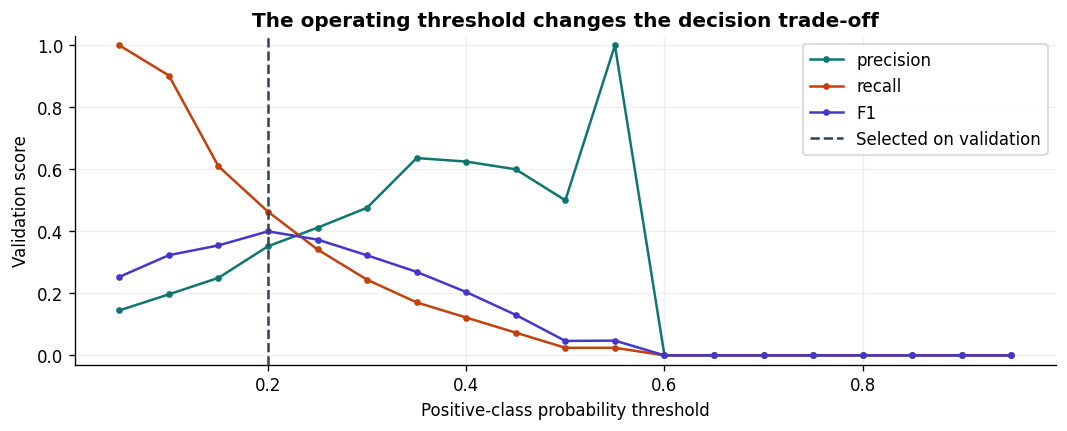

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.7))
for metric, color in [("precision", "#0f766e"), ("recall", "#c2410c"), ("F1", "#4338ca")]:
    ax.plot(threshold_results["threshold"], threshold_results[metric],
            marker="o", markersize=3, label=metric, color=color)
ax.axvline(chosen_threshold, color="#334155", linestyle="--", label="Selected on validation")
ax.set(xlabel="Positive-class probability threshold", ylabel="Validation score",
       ylim=(-0.03, 1.03), title="The operating threshold changes the decision trade-off")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

**Figure takeaway:** higher thresholds predict fewer positives. Choose the operating point using the stated objective and development data; the largest score on this grid is a selection result, not an unbiased performance estimate.

,accuracy,balanced_accuracy,precision,recall,F1
Majority baseline,0.872,0.500,0.000,0.000,0.000
Logistic at 0.50,0.872,0.500,0.000,0.000,0.000
Logistic at frozen threshold,0.812,0.612,0.298,0.341,0.318


Test ROC-AUC: 0.688
Test average precision: 0.320
Test log loss: 0.354
Test positive prevalence (AP reference): 0.128


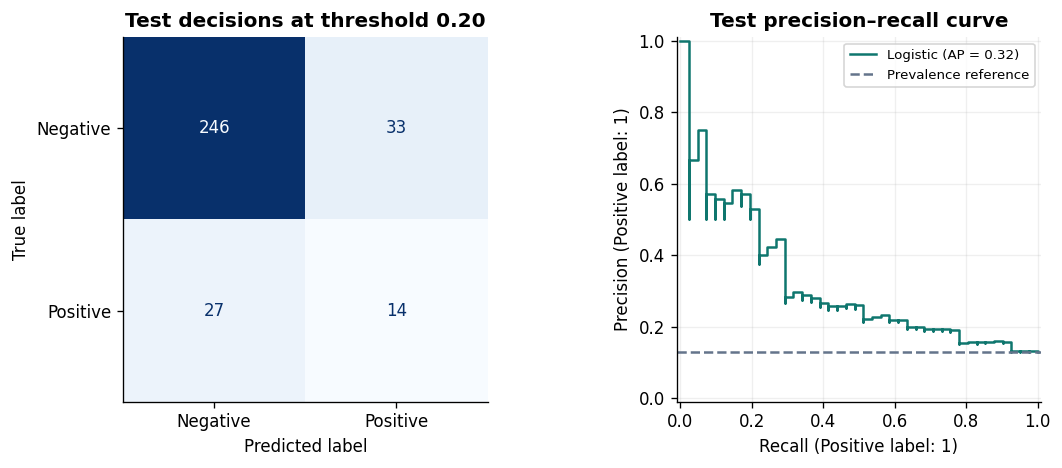

In [6]:
# Final evaluation: no tuning below this point.
test_prob = search.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = dummy.predict(X_test)

def decision_metrics(labels, predictions):
    return {"accuracy": accuracy_score(labels, predictions),
            "balanced_accuracy": balanced_accuracy_score(labels, predictions),
            "precision": precision_score(labels, predictions, zero_division=0),
            "recall": recall_score(labels, predictions, zero_division=0),
            "F1": f1_score(labels, predictions, zero_division=0)}

display(pd.DataFrame({
    "Majority baseline": decision_metrics(y_test, baseline_pred),
    "Logistic at 0.50": decision_metrics(y_test, test_prob >= 0.5),
    "Logistic at frozen threshold": decision_metrics(y_test, test_pred),
}).T.round(3))
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_prob):.3f}")
print(f"Test average precision: {average_precision_score(y_test, test_prob):.3f}")
print(f"Test log loss: {log_loss(y_test, test_prob):.3f}")
print(f"Test positive prevalence (AP reference): {y_test.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["Negative", "Positive"]).plot(
                           ax=axes[0], colorbar=False, cmap="Blues")
axes[0].grid(False)
axes[0].set_title(f"Test decisions at threshold {chosen_threshold:.2f}")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1],
                                         name="Logistic", color="#0f766e")
axes[1].axhline(y_test.mean(), linestyle="--", color="#64748b", label="Prevalence reference")
axes[1].set_title("Test precision–recall curve")
axes[1].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

**Read the result:** the majority baseline can look strong on accuracy while missing every positive. The selected threshold trades precision for recall; selection on validation does not guarantee the best test F1. Treat the test curve as a report, not an invitation to choose another threshold. The categorical column was deliberately random, so encoding it correctly does not imply it adds predictive value.

<a id="section-20"></a>

## 20. Error analysis and statistical uncertainty

**Error analysis:** inspect false positives, false negatives, or largest residuals. Slice by relevant groups, time, feature ranges, and data quality. Count examples in each slice; a score based on three cases is unstable. Investigate mislabeled data and deployment mismatch before adding complexity.

**Uncertainty:** separate variability from finite evaluation data, training randomness, and distribution change. Bootstrap intervals resample evaluation units; group or temporal data require appropriate resampling. A narrow interval from one fixed model does not describe uncertainty about all possible future environments.

**Comparing models:** evaluate on the same held-out cases; paired comparisons can be more informative than independent score intervals. Account for repeated experiments and metric selection. Reusing a test set for many decisions turns it into development data.

**Explainability:** coefficients depend on scaling and correlated features. Permutation importance measures score degradation after shuffling a feature; correlated substitutes can hide importance. SHAP-style explanations describe model behavior under assumptions about feature dependence; they do not establish causation.

The next interval estimates test-sample variability of F1 for the already fixed model and threshold. It does not refit the model or justify retuning it.

In [7]:
bootstrap_rng = np.random.default_rng(RANDOM_STATE)
bootstrap_f1 = []
for _ in range(1000):
    sample_ids = bootstrap_rng.integers(0, len(y_test), size=len(y_test))
    bootstrap_f1.append(f1_score(y_test[sample_ids], test_pred[sample_ids], zero_division=0))
lower, upper = np.quantile(bootstrap_f1, [0.025, 0.975])
print(f"Fixed-model test F1: {f1_score(y_test, test_pred):.3f}")
print(f"Approximate 95% percentile-bootstrap interval: [{lower:.3f}, {upper:.3f}]")
print("Assumes independent, representative test rows; excludes training/selection uncertainty.")

Fixed-model test F1: 0.318
Approximate 95% percentile-bootstrap interval: [0.196, 0.449]
Assumes independent, representative test rows; excludes training/selection uncertainty.


<a id="section-21"></a>

## 21. Deployment, monitoring, and responsible ML

The deployable artifact is **preprocessing + model + decision rule + schema**, together with versions and documentation. Preserve feature names, ordering, dtypes, category handling, random seeds, and training-data provenance. Never load an untrusted pickle/joblib artifact.

| Monitor | What it can reveal | Response |
|---|---|---|
| Schema, missingness, range checks | Broken input contracts | Validate and investigate upstream changes |
| Latency, memory, failures | Serving constraints | Optimize, provide fallback, or roll back |
| Feature distributions | Covariate drift: changes in $P(X)$ | Check whether outcome performance changes |
| Label prevalence | Prior shift: changes in $P(y)$ | Reassess decisions and probability calibration |
| Outcome metrics and slices | Concept drift: changes in $P(y\mid X)$ or other degradation | Diagnose, retrain, and revalidate |

Drift is a signal to investigate, not proof that performance declined; stable inputs do not prove stable outcomes. Ground-truth labels may arrive late. Log predictions and eventual outcomes under appropriate privacy constraints.

Use shadow evaluation or staged rollout when appropriate, compare real outcomes with the intended baseline, and maintain a rollback path. A/B tests support causal comparisons when randomization and analysis are sound; offline accuracy alone does not establish product benefit.

**Responsible ML:** check consent/provenance, minimize sensitive data, assess group-level errors and accessibility, document limitations, and provide human review where warranted. Removing a sensitive column does not remove proxies or guarantee fairness; different fairness criteria can conflict.

<a id="section-22"></a>

## 22. Guide to the algorithms notebook

Continue with [ml-algorithms-explained.ipynb](ml-algorithms-explained.ipynb). It follows dataset preview → split → fit → predict → evaluate and includes explanatory images.

| Companion section | Bring these concepts with you |
|---|---|
| 3. Linear Regression | Loss, residuals, coefficient assumptions, MAE/RMSE/R² |
| 4. Logistic Regression | Log-odds, cross-entropy, calibration, thresholds |
| 5. K-Nearest Neighbors | Scaling, distance, k, bias–variance |
| 6. Support Vector Machine | Margin, C, kernels, scale |
| 7. Naive Bayes Classifier | Bayes rule and conditional independence |
| 8. Decision Tree | Impurity, depth, variance |
| 9–10. Bagging, Random Forest, Boosting | Variance reduction, sequential fitting, ensemble diversity |
| 11. Neural Networks / Deep Learning | Activations, gradients, regularization |
| 12. K-Means Clustering | Geometry, arbitrary cluster IDs, silhouette |
| 13–14. Dimensionality Reduction / PCA | Centering/scaling, explained variance, leakage |

**Interpret the examples correctly:** supervised sections use different synthetic datasets, so their printed scores are not a fair algorithm leaderboard. Most demonstrate a single train/test split rather than full tuning. K-means and PCA are exploratory full-dataset demonstrations; if used in a predictive workflow, fit transformations on training data only. Fixed seeds make examples repeatable, not universally representative.

The repository's existing `export_notebook_to_html.py` targets the algorithms notebook specifically. Read this companion directly in a notebook viewer; its saved outputs and mathematical notation are part of the learning material.

<a id="section-23"></a>

## 23. Interview questions with concise answers

Try answering each question in 30–60 seconds: **definition → example or trade-off → verification**. These are general practice questions, not a prediction of any particular interview. Answers are intentionally short; use the relevant notes for detail.

### Fundamentals and data

**Q1. How is classification different from regression?**

Classification predicts discrete labels or their probabilities; regression predicts a numeric quantity. A numeric code such as 0/1 can still represent a classification target.

**Q2. What is the difference between a parameter and a hyperparameter?**

A parameter is learned during fitting, such as a coefficient. A hyperparameter controls the learning procedure, such as C or tree depth, and is selected with development data.

**Q3. Why do we need a validation set if we already have a test set?**

Validation supports choices. The untouched test estimates how the chosen procedure performs on new data. Tuning against test scores contaminates that estimate.

**Q4. What is data leakage? Give two examples.**

Information unavailable at prediction time influences training or evaluation: fitting a scaler before splitting, or using a post-outcome field to predict that outcome. A pipeline fixes the first, not the second.

**Q5. When is a random train/test split inappropriate?**

When rows share entities, near-duplicates, or temporal dependence. Split by group or forward in time to match how the model will encounter new data.

**Q6. What is stratification, and what does it not solve?**

It approximately preserves label proportions. It does not prevent the same user appearing in both partitions or protect against future-to-past leakage.

**Q7. How would you handle missing data?**

Investigate the missingness mechanism, compare simple training-fold imputations, consider indicators, and validate the result. Dropping rows can bias the sample; filling all missing values with zero can change the meaning.

**Q8. Does standardization make the data normally distributed?**

No. It shifts and rescales using mean and standard deviation; it does not change the distribution's fundamental shape.

**Q9. Does zero correlation mean independence?**

No. For symmetric X, X and X squared can have zero linear correlation while being dependent. Independence implies zero covariance when the relevant moments exist.

**Q10. What should be defined before selecting an algorithm?**

Prediction unit and time, target horizon, available inputs, deployment population, baseline, success metric, and error costs. These determine the split and what a useful result means.

### Learning and algorithms

**Q11. Explain the bias–variance trade-off.**

Bias is systematic error; variance is sensitivity to the training sample. Increasing capacity often lowers bias but can raise variance. Compare training/validation behavior and diagnose data mismatch before choosing a remedy.

**Q12. How would you reduce overfitting?**

First verify the split and leakage controls. Then try simpler models, stronger regularization, early stopping, more representative training data, or valid augmentation; compare using development data.

**Q13. Will more data always improve a model?**

No. Extra biased, mislabeled, or irrelevant data may not help. More representative data often helps high variance; underfitting can require better features or a different model.

**Q14. Why is logistic regression a classifier?**

It models class probability by applying a sigmoid to a linear score in the binary case. The log-odds are linear in features; a threshold turns probability into a label.

**Q15. Must linear-regression features be normally distributed?**

No. Normality assumptions used in some classical inference concern errors, not features. Predictive adequacy and residual behavior should be evaluated separately.

**Q16. How do L1 and L2 differ?**

L1 can set coefficients exactly to zero; L2 shrinks them continuously. Scale inputs and validate the penalty. L1 selection can be unstable among highly correlated predictors.

**Q17. What happens when C increases in a regularized logistic model or SVM?**

Regularization becomes weaker, generally allowing a closer fit to training data. Validation determines whether this improves generalization.

**Q18. What happens when k increases in KNN?**

Predictions become smoother and less local, often lowering variance while increasing bias. Scale features and tune k with a suitable validation scheme.

**Q19. What does the kernel trick do?**

It evaluates inner products in an implicit feature space without explicitly constructing all mapped features. This supports nonlinear decision boundaries; it does not guarantee cheap computation.

**Q20. What is naive about Naive Bayes?**

It assumes features are conditionally independent given the class. This is not unconditional independence. Useful classification can still occur when the assumption is imperfect, though probabilities may suffer.

**Q21. Compare bagging and boosting.**

Bagging combines models trained on bootstrap samples, usually reducing variance. Boosting builds an additive model sequentially to improve an objective. Both can overfit depending on model complexity and data.

**Q22. Why can a random forest improve on bagged trees?**

Feature subsampling reduces correlation among trees, which can improve variance reduction from averaging. Benefits depend on the strength and diversity of the individual trees.

**Q23. How does gradient boosting differ from AdaBoost?**

Gradient boosting fits new learners to negative loss gradients. Classic AdaBoost increases emphasis on misclassified examples through weights. They are related boosting approaches, not identical update rules.

**Q24. What is the difference between backpropagation and gradient descent?**

Backpropagation computes derivatives using the chain rule. Gradient descent is an update rule that uses those derivatives. Other optimizers can use the same backpropagated gradients.

### Evaluation and reasoning

**Q25. A model has 99% accuracy. Is it good?**

Not enough information. Check prevalence, the baseline, leakage, positive-class recall, precision, subgroup results, and error costs. Predicting the majority class can reach 99% in a 1%-positive dataset.

**Q26. When would you prioritize precision over recall?**

When false alerts are costly, such as a limited manual-review queue. Prioritize recall when missed positives are expensive, while checking that the resulting alert volume is practical.

**Q27. Why use F1 rather than accuracy?**

F1 focuses on precision and recall for the chosen positive class and ignores true negatives. It is useful for some retrieval goals, but does not encode arbitrary business costs or calibration.

**Q28. Can ROC-AUC be high while precision is poor?**

Yes. With rare positives, even a small false-positive rate can produce many false alerts. Inspect the PR curve and performance at the actual operating threshold.

**Q29. Can R² be negative?**

Yes. Predictions can have more squared error than the evaluation-set mean baseline. R² is not bounded below by zero on held-out data.

**Q30. How do you choose a classification threshold?**

Specify costs or constraints first, then choose on validation data or out-of-fold predictions. Freeze it before final testing. A default 0.5 threshold need not meet the objective.

**Q31. What is probability calibration?**

Predicted probabilities should agree with observed frequencies across comparable cases. A well-ranked model can be miscalibrated. Assess reliability and use development-only calibration fitting.

**Q32. How do you handle class imbalance?**

Use appropriate metrics and a suitable split; compare class weighting, within-fold resampling, and threshold changes. Keep evaluation representative of deployment prevalence and inspect minority-class sample size.

**Q33. Why can feature selection before CV be wrong?**

The selected features may already encode information from the validation folds, especially when selection uses labels. Put selection inside the fitted pipeline for each fold.

**Q34. What does a confidence interval around a test metric tell you?**

It describes uncertainty under a particular sampling procedure and assumptions. A fixed-model bootstrap interval does not capture retraining variability, selection bias, or future drift.

**Q35. A model performs well offline but poorly after deployment. What do you check?**

Feature timing and leakage, preprocessing parity, schema changes, training/serving population mismatch, delayed labels, threshold/calibration changes, and performance by time and group.

**Q36. Can feature importance tell us what intervention will help?**

No. It describes predictive dependence in a fitted model, which may reflect confounding or proxies. Causal effects require additional assumptions and an appropriate design.

### Unsupervised learning and practical scenarios

**Q37. How do you select k for K-means?**

Compare inertia patterns, silhouette, stability across seeds/samples, and domain usefulness. There may be no clear elbow. Scale appropriately and question whether compact Euclidean clusters fit the data.

**Q38. Is PCA supervised? Does it preserve predictive information?**

PCA is unsupervised and maximizes retained variance, not target relevance. A low-variance direction can be predictive. Validate component count inside the training pipeline.

**Q39. Can you compare predicted cluster IDs directly with class IDs?**

No. Cluster numbering is arbitrary. Use permutation-invariant measures such as adjusted Rand index when reference labels exist, and inspect whether the grouping is useful.

**Q40. Training error and validation error are both high. What next?**

Check target quality, preprocessing, optimization, and baseline difficulty. Then consider richer features, more capacity, or less regularization. More data alone may not fix underfitting.

**Q41. How would you design a churn-model experiment?**

Define an observation date and future churn window, construct historical features, use temporal/entity-aware validation, compare a baseline, choose a cost-aware threshold, then test on a later untouched period.

**Q42. A dataset has 200 features and only 300 rows. What do you try?**

Begin with regularized simple models and careful validation, reduce irrelevant features inside folds, inspect leakage, and quantify uncertainty. A complex network is not justified by feature count alone.

**Q43. How would you make an experiment reproducible?**

Record data version and split IDs, feature definitions, seeds, library versions, pipeline settings, search space, and metrics. Seeds alone do not guarantee identical results across hardware or software.

**Q44. What should be delivered besides a trained model?**

The full preprocessing and decision pipeline, input schema, environment/dependency record, evaluation and limitations, inference checks, monitoring plan, and rollback procedure.

<a id="section-24"></a>

## 24. Quick revision checklist and references

### Quick revision checklist

- **Frame:** what is predicted, for whom, at what time, and using which available information?
- **Audit:** missingness, duplicates, labels, population, and provenance.
- **Split:** independent rows, groups, or time; preserve an untouched final test.
- **Baseline:** a simple rule or dummy estimator with the same evaluation protocol.
- **Preprocess:** fit imputation, encoding, scaling, selection, and PCA inside training folds.
- **Learn:** distinguish parameters, hyperparameters, loss, optimization, and regularization.
- **Diagnose:** compare train/validation behavior; inspect representative errors and slices.
- **Evaluate:** use task-relevant metrics; distinguish ranking, calibration, and decisions.
- **Select:** tune models and thresholds using development data; report uncertainty honestly.
- **Deploy:** preserve the full pipeline, monitor outcomes and drift, document limitations.

### Formula recall

| Concept | Recall |
|---|---|
| Linear prediction | $\hat y=w^Tx+b$ |
| Sigmoid | $\sigma(z)=1/(1+e^{-z})$ |
| Binary cross-entropy | $-[y\log p+(1-y)\log(1-p)]$ |
| Gradient update | $\theta\leftarrow\theta-\eta\nabla J(\theta)$ |
| Precision / recall | $TP/(TP+FP)$ / $TP/(TP+FN)$ |
| F1 | $2TP/(2TP+FP+FN)$ |
| RMSE | $\sqrt{\mathrm{mean}((y-\hat y)^2)}$ |

### Further reading

The notes synthesize standard ML concepts. Use these primary documentation pages for implementation details and to check conventions for your installed version:

- [Data leakage and preprocessing pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [Cross-validation and evaluation design](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html)
- [Linear models and regularization](https://scikit-learn.org/stable/modules/linear_model.html)
- [Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html)
- [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

**Next:** work through the [algorithms notebook](ml-algorithms-explained.ipynb), explaining each split, transformation, fitting call, and metric before running it.